n_estimators=50 → MAE = 1.032 heures
n_estimators=100 → MAE = 1.031 heures
n_estimators=150 → MAE = 1.031 heures
n_estimators=200 → MAE = 1.031 heures
n_estimators=250 → MAE = 1.031 heures

🔹 Meilleur n_estimators = 250 avec MAE = 1.031 heures


c:\Users\azizi\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\ensemble\_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(
c:\Users\azizi\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\ensemble\_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


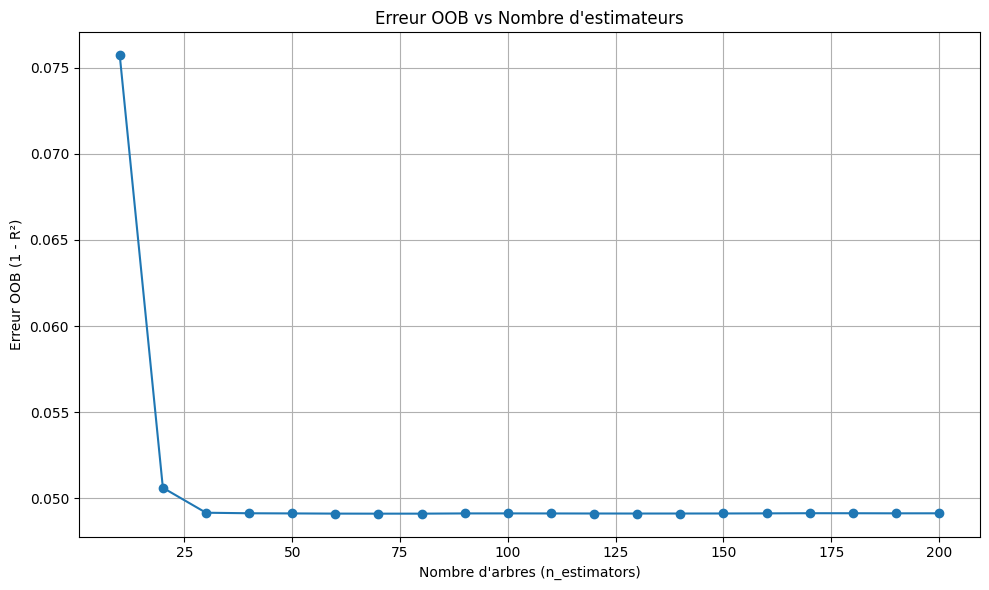

MAE : 1.0 heure
RMSE : 1.4 heure
R² : 0.95


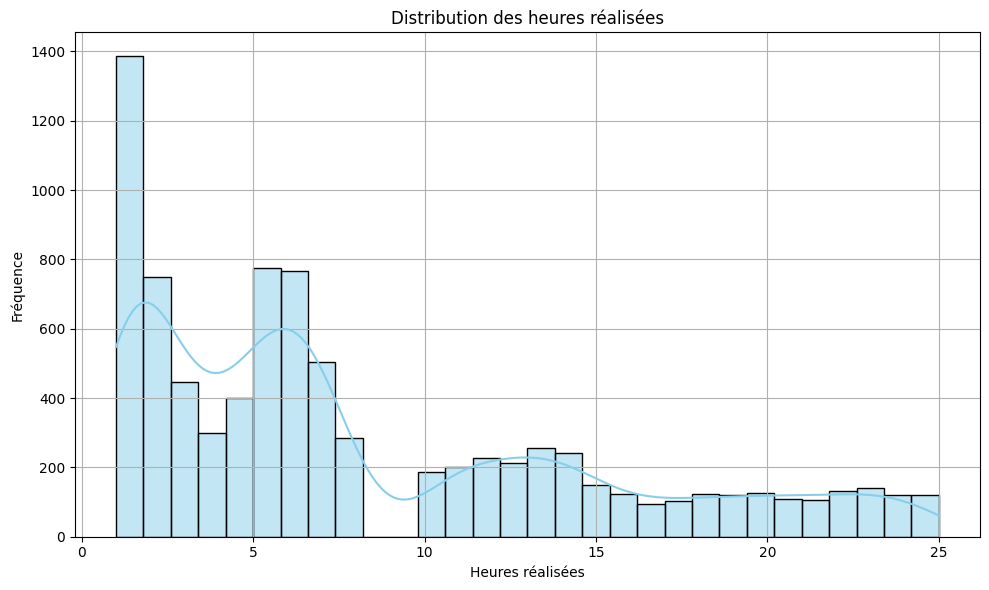

In [24]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# 1️⃣ Charger les données depuis le fichier Excel
file_path = "donnees_tiers.xlsx"  # Remplace par ton chemin réel
df = pd.read_excel(file_path)

# 2️⃣ Encoder les variables catégoriques
label_enc_eq = LabelEncoder()
label_enc_pb = LabelEncoder()

df["Libellé Equipement"] = label_enc_eq.fit_transform(df["Libellé Equipement"])
df["Titre D.I"] = label_enc_pb.fit_transform(df["Titre D.I"])

# 3️⃣ Définir les variables X (entrée) et y (cible)
X = df[["Libellé Equipement", "Titre D.I"]]
y = df["H. réalisées"]

# 4️⃣ Diviser les données en train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5️⃣ Boucle pour tester différents `n_estimators`
best_n = None
best_mae = float("inf")
results = []

for n in range(50, 251, 50):  # Teste n_estimators de 50 à 250 par pas de 50
    model = RandomForestRegressor(n_estimators=n, random_state=42)
    model.fit(X_train, y_train)
    
    # Évaluer le modèle
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    
    print(f"n_estimators={n} → MAE = {mae:.3f} heures")
    
    # Sauvegarder les résultats
    results.append((n, mae))
    
    # Vérifier si c'est le meilleur modèle
    if mae < best_mae:
        best_mae = mae
        best_n = n

# 6️⃣ Afficher la meilleure valeur
print(f"\n🔹 Meilleur n_estimators = {best_n} avec MAE = {best_mae:.3f} heures")

# 7️⃣ Entraîner le modèle final avec le meilleur n_estimators
final_model = RandomForestRegressor(n_estimators=best_n, random_state=42)
final_model.fit(X_train, y_train)

# 8️⃣ Fonction de prédiction
def predict_hours(equipement, probleme):
    eq_encoded = label_enc_eq.transform([equipement])[0]
    pb_encoded = label_enc_pb.transform([probleme])[0]
    predicted_hours = final_model.predict([[eq_encoded, pb_encoded]])[0]
    return round(predicted_hours, 1)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Prédictions sur le test
y_pred = final_model.predict(X_test)

# Calcul des métriques
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
oob_errors = []
n_estimators_range = range(10, 201, 10)

for n in n_estimators_range:
    model = RandomForestRegressor(
        n_estimators=n,
        oob_score=True,
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    )
    model.fit(X_train, y_train)
    oob_error = 1 - model.oob_score_
    oob_errors.append(oob_error)

# Affichage
plt.figure(figsize=(10, 6))
plt.plot(n_estimators_range, oob_errors, marker='o')
plt.title("Erreur OOB vs Nombre d'estimateurs")
plt.xlabel("Nombre d'arbres (n_estimators)")
plt.ylabel("Erreur OOB (1 - R²)")
plt.grid(True)
plt.tight_layout()
plt.show()
# Affichage formaté
print(f"MAE : {mae:.1f} heure")
print(f"RMSE : {rmse:.1f} heure")
print(f"R² : {r2:.2f}")
# Calcul des métriques
import seaborn as sns

# 📊 Distribution des heures réalisées
plt.figure(figsize=(10, 6))
sns.histplot(y, kde=True, bins=30, color='skyblue')
plt.title("Distribution des heures réalisées")
plt.xlabel("Heures réalisées")
plt.ylabel("Fréquence")
plt.grid(True)
plt.tight_layout()
plt.show()





In [20]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestRegressor, BaggingRegressor
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

# 1️⃣ Charger les données depuis le fichier Excel
file_path = "donnees_tiers.xlsx"  # Remplace par ton chemin réel
df = pd.read_excel(file_path)

# 2️⃣ Encoder les variables catégoriques
label_enc_eq = LabelEncoder()
label_enc_pb = LabelEncoder()

df["Libellé Equipement"] = label_enc_eq.fit_transform(df["Libellé Equipement"])
df["Titre D.I"] = label_enc_pb.fit_transform(df["Titre D.I"])

# 3️⃣ Définir les variables X (entrée) et y (cible)
X = df[["Libellé Equipement", "Titre D.I"]]
y = df["H. réalisées"]

# 4️⃣ Diviser les données en train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5️⃣ Boucle pour tester différents `n_estimators` avec Bagging
best_n = None
best_mae = float("inf")
results = []

for n in range(50, 251, 50):  # Teste n_estimators de 50 à 250 par pas de 50
    # Utilisation de Bagging avec RandomForestRegressor comme base
    base_model = RandomForestRegressor(random_state=42)
    model = BaggingRegressor(base_model, n_estimators=n, random_state=42)
    
    model.fit(X_train, y_train)
    
    # Évaluer le modèle
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    
    # Sauvegarder les résultats
    results.append((n, mae))
    
    # Vérifier si c'est le meilleur modèle
    if mae < best_mae:
        best_mae = mae
        best_n = n

# 6️⃣ Afficher la meilleure valeur
print(f"\n🔹 Meilleur n_estimators = {best_n} avec MAE = {best_mae:.3f} heures")

# 7️⃣ Entraîner le modèle final avec le meilleur n_estimators
base_model = RandomForestRegressor(random_state=42)
final_model = BaggingRegressor(base_model, n_estimators=best_n, random_state=42)
final_model.fit(X_train, y_train)

# 8️⃣ Fonction de prédiction
def predict_hours(equipement, probleme):
    eq_encoded = label_enc_eq.transform([equipement])[0]
    pb_encoded = label_enc_pb.transform([probleme])[0]
    predicted_hours = final_model.predict([[eq_encoded, pb_encoded]])[0]
    return round(predicted_hours, 1)

# 9️⃣ Prédictions et évaluation sur le test
y_pred = final_model.predict(X_test)

# Calcul des métriques
mae = mean_absolute_error(y_test, y_pred)

# Affichage formaté
print(f"MAE : {mae:.1f} heure")

# Plot the MAE for different n_estimators
n_values = [result[0] for result in results]
mae_values = [result[1] for result in results]

plt.figure(figsize=(10, 6))
plt.plot(n_values, mae_values, marker='o', color='b', label='MAE for Bagging')
plt.title("Bagging Regressor: MAE vs. n_estimators")
plt.xlabel("Number of Estimators (n_estimators)")
plt.ylabel("Mean Absolute Error (MAE)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# 10️⃣ Randomly select 10 test samples for prediction vs real values
random_indices = np.random.choice(len(X_test), size=10, replace=False)
real_values = y_test.iloc[random_indices].values
predicted_values = y_pred[random_indices]

# Plot predicted vs real values for 10 random examples
plt.figure(figsize=(10, 6))
plt.scatter(real_values, predicted_values, color='b', label="Predicted vs Real")
plt.plot([min(real_values), max(real_values)], [min(real_values), max(real_values)], color='r', linestyle='--', label="Ideal Line (Real = Predicted)")
plt.title("Predicted vs Real Values (10 Random Examples)")
plt.xlabel("Real Values (Actual Hours)")
plt.ylabel("Predicted Values (Predicted Hours)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Exemple de prédiction
equipement_test = "stacker terex"
probleme_test = "problem chaine"
predicted_time = predict_hours(equipement_test, probleme_test)
print(f"\nPrédiction : {equipement_test} avec {probleme_test} → {predicted_time} heures")

KeyboardInterrupt: 

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# 1️⃣ Charger les données
file_path = "donnees_tiersx.xlsx"
df = pd.read_excel(file_path)

# 2️⃣ One-Hot Encoding pour les catégories
encoder = OneHotEncoder(sparse_output=False)
encoded_features = encoder.fit_transform(df[["Libellé Equipement", "Titre D.I"]])
feature_names = encoder.get_feature_names_out()


# Convertir en DataFrame
X_encoded = pd.DataFrame(encoded_features, columns=feature_names)

# Ajouter la colonne cible
y = df["H. réalisées"]

# 3️⃣ Split Train/Test
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

# 4️⃣ Entraîner Random Forest avec meilleure valeur `n_estimators`
best_n = 200  # Ajustable après test
rf_model = RandomForestRegressor(n_estimators=best_n, random_state=42)
rf_model.fit(X_train, y_train)

# 5️⃣ Évaluation
y_pred = rf_model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
print(f"📊 Performance du modèle → MAE = {mae:.3f} heures")

# 6️⃣ Fonction de prédiction avec One-Hot Encoding
def predict_hours(equipement, probleme):
    # Encoder les entrées
    input_df = pd.DataFrame([[equipement, probleme]], columns=["Libellé Equipement", "Titre D.I"])
    input_encoded = encoder.transform(input_df)
    
    # Prédiction
    predicted_hours = rf_model.predict(input_encoded)[0]
    return round(predicted_hours, 1)

# 7️⃣ Test avec différents équipements
equipements_test = ["GRUE PORTUAIRE LHM400", "SPREADEUR AUTOMATIQUE BROMMA N01"]
probleme_test = "problem chaine"

for equip in equipements_test:
    predicted_time = predict_hours(equip, probleme_test)
    print(f"\n📌 Prédiction : {equip} avec {probleme_test} → {predicted_time} heures")
import joblib

import joblib

# Save the model and encoder
joblib.dump(rf_model, "random_forest_model.pkl")
joblib.dump(encoder, "onehot_encoder.pkl")

print("✅ Modèle et encodeur sauvegardés.")



📊 Performance du modèle → MAE = 1.045 heures

📌 Prédiction : GRUE PORTUAIRE LHM400 avec problem chaine → 6.2 heures

📌 Prédiction : SPREADEUR AUTOMATIQUE BROMMA N01 avec problem chaine → 5.9 heures


c:\Users\azizi\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(
c:\Users\azizi\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestRegressor was fitted with feature names
  warnings.warn(


['onehot_encoder.pkl']

In [8]:
import streamlit as st
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
import joblib

# 🔁 Load your pre-trained model and encoder
rf_model = joblib.load("random_forest_model.pkl")
encoder = joblib.load("onehot_encoder.pkl")

# List of equipments
equipements = [
    "GRUE PORTUAIRE LHM400", "GRUE PORTUAIRE LHM200", "GRUE PORTUAIRE LHM120",
    "CHARIOT TEREX 10T N04", "CHARIOT TEREX 10T N02", "CHARIOT TEREX 10T N06",
    "SPREADEUR AUTOMATIQUE BROMMA N04", "SPREADEUR AUTOMATIQUE BROMMA N01", 
    "SPREADEUR AUTOMATIQUE BROMMA N03", "stacker terex", "stacker kalmar", "stacker LINDE"
]

problemes_base = {
    "problem electrique": (4, 7),
    "problem arret moteur": (15, 25),
    "problem chaine": (5, 8),
    "problem roue": (1, 4),
    "problem fuite": (10, 15),
    "problem piston et huile": (1, 2)
}

# 🎛️ Streamlit UI
st.title("🛠️ Prédiction du Temps de Réparation")

selected_equipement = st.selectbox("Sélectionnez un équipement", equipements)
selected_probleme = st.selectbox("Sélectionnez un problème", list(problemes_base.keys()))

# 🔍 Prediction function
def predict_hours(equipement, probleme):
    input_df = pd.DataFrame([[equipement, probleme]], columns=["Libellé Equipement", "Titre D.I"])
    input_encoded = encoder.transform(input_df)
    predicted_hours = rf_model.predict(input_encoded)[0]
    return round(predicted_hours, 1)

if st.button("Prédire le temps de réparation"):
    result = predict_hours(selected_equipement, selected_probleme)
    st.success(f"⏱️ Temps de réparation estimé : **{result} heures**")


2025-05-11 18:50:42.530 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-05-11 18:50:42.530 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-05-11 18:50:42.531 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-05-11 18:50:42.531 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-05-11 18:50:42.532 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-05-11 18:50:42.532 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-05-11 18:50:42.532 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2025-05-11 18:50:42.533 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

                 Libellé Equipement                Titre D.I  H. réalisées  \
0  SPREADEUR AUTOMATIQUE BROMMA N04     problem arret moteur          21.4   
1             CHARIOT TEREX 10T N04     problem arret moteur          15.3   
2                    stacker kalmar             problem roue           1.8   
3  SPREADEUR AUTOMATIQUE BROMMA N01       problem electrique           4.7   
4             CHARIOT TEREX 10T N02  problem piston et huile           1.7   

              Date D.I   Date debut travail  Date fin de travail  
0   28/09/2023 4:42 am  26/09/2023 12:33 am   26/09/2023 9:57 pm  
1   24/05/2023 4:34 pm  21/05/2023 11:49 pm   22/05/2023 3:07 pm  
2  13/06/2023 10:56 pm   12/06/2023 7:03 pm   12/06/2023 8:51 pm  
3   11/10/2023 5:21 pm   09/10/2023 3:01 pm   09/10/2023 7:43 pm  
4   17/04/2023 3:14 am   14/04/2023 9:41 am  14/04/2023 11:23 am  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8500 entries, 0 to 8499
Data columns (total 6 columns):
 #   Column            

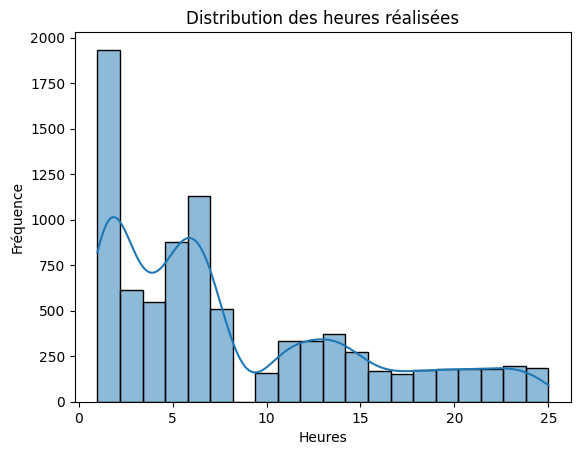

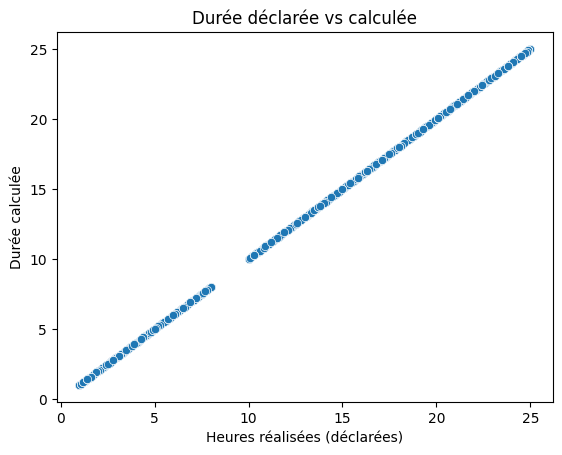

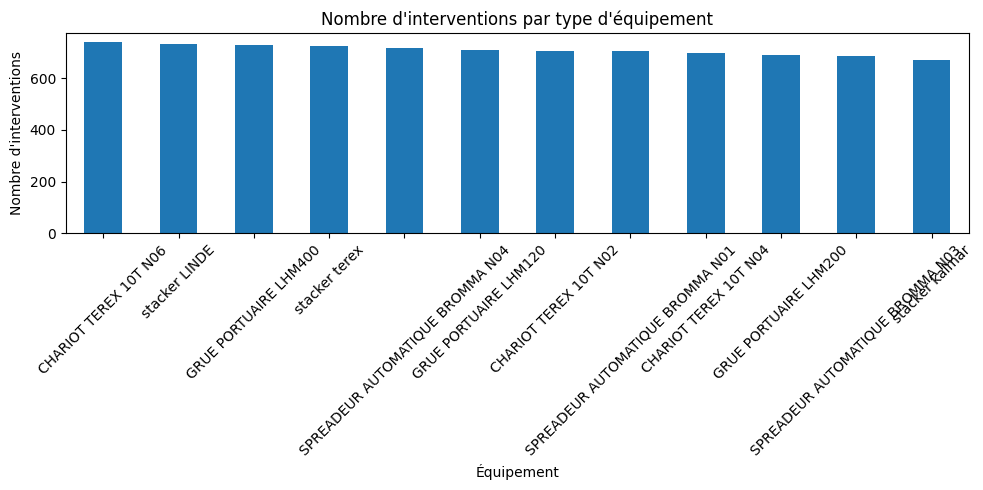

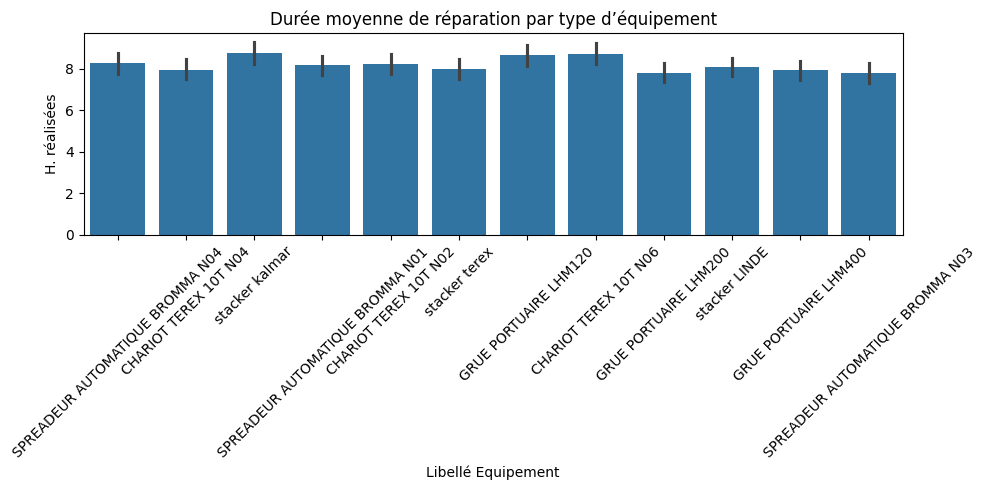

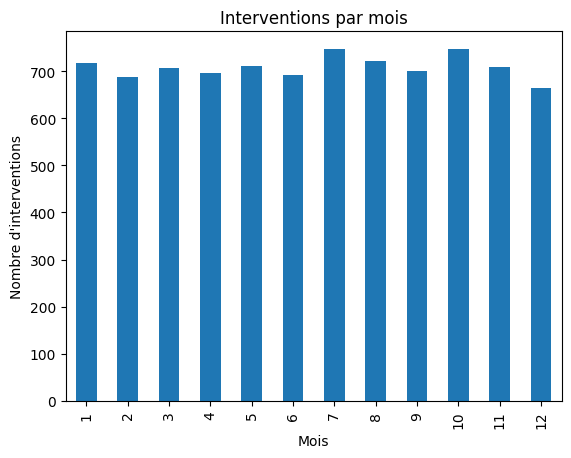

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Charger le fichier Excel ou CSV
df = pd.read_excel("donnees_tiers.xlsx")  # ou pd.read_csv()

# Afficher les 5 premières lignes
print(df.head())

# Vérifier les types et valeurs manquantes
print(df.info())
print(df.isnull().sum())

# Transformer les dates au bon format
df["Date D.I"] = pd.to_datetime(df["Date D.I"], format="%d/%m/%Y %I:%M %p", dayfirst=True)
df["Date debut travail"] = pd.to_datetime(df["Date debut travail"], format="%d/%m/%Y %I:%M %p", dayfirst=True)
df["Date fin de travail"] = pd.to_datetime(df["Date fin de travail"], format="%d/%m/%Y %I:%M %p", dayfirst=True)


# Ajouter des colonnes utiles
df["Durée calculée (heures)"] = (df["Date fin de travail"] - df["Date debut travail"]).dt.total_seconds() / 3600
df["Jour semaine"] = df["Date D.I"].dt.day_name()
df["Mois"] = df["Date D.I"].dt.month

# Distribution des heures réalisées
sns.histplot(df["H. réalisées"].dropna(), bins=20, kde=True)
plt.title("Distribution des heures réalisées")
plt.xlabel("Heures")
plt.ylabel("Fréquence")
plt.show()

# Comparaison entre durée déclarée et durée calculée
sns.scatterplot(x="H. réalisées", y="Durée calculée (heures)", data=df)
plt.title("Durée déclarée vs calculée")
plt.xlabel("Heures réalisées (déclarées)")
plt.ylabel("Durée calculée")
plt.show()

# Nombre d'interventions par équipement
plt.figure(figsize=(10, 5))
df["Libellé Equipement"].value_counts().plot(kind='bar')
plt.title("Nombre d'interventions par type d'équipement")
plt.xlabel("Équipement")
plt.ylabel("Nombre d'interventions")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Moyenne des heures réalisées par type d’équipement
plt.figure(figsize=(10, 5))
sns.barplot(x="Libellé Equipement", y="H. réalisées", data=df)
plt.title("Durée moyenne de réparation par type d’équipement")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Nombre d’interventions par mois
df["Mois"].value_counts().sort_index().plot(kind='bar')
plt.title("Interventions par mois")
plt.xlabel("Mois")
plt.ylabel("Nombre d'interventions")
plt.show()


ValueError: could not convert string to float: 'CHARIOT TEREX 10T N02'

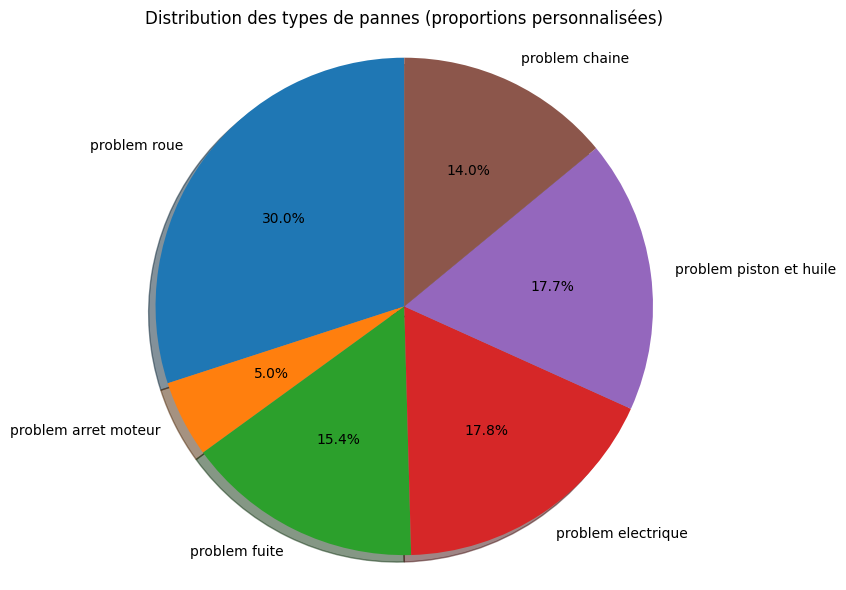

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Définir manuellement les catégories et leurs proportions
labels = [
    "problem roue",
    "problem arret moteur",
    "problem fuite",
    "problem electrique",
    "problem piston et huile",
    "problem chaine"
]

# Fixer les proportions : 30% et 5%, les autres random mais normalisées pour total = 1
fixed = {"problem roue": 0.30, "problem arret moteur": 0.05}
others = ["problem fuite", "problem electrique", "problem piston et huile", "problem chaine"]
random_parts = np.random.rand(len(others))
random_parts = random_parts / random_parts.sum() * (1 - sum(fixed.values()))

# Assembler les parts finales
sizes = []
for label in labels:
    if label in fixed:
        sizes.append(fixed[label])
    else:
        sizes.append(random_parts[others.index(label)])

# Afficher le camembert
plt.figure(figsize=(8, 6))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90, shadow=True)
plt.title("Distribution des types de pannes ")
plt.axis('equal')
plt.tight_layout()
plt.show()
